# Week 10: Instrumental variables
**DS-UA 201 · Fall 2026**  
**Center for Data Science, New York University**  

**TA: Xiang Gao**

Nov 13, 2026

[Open in Colab](https://colab.research.google.com/github/xgao0o/DS-UA_201-Causal-Inference-Fall-2026/blob/main/labs/10-Instrumental_Variables.ipynb) (available after publication to the repository).


The Sesame Street file contains **real historical teaching data**. The weak-instrument and collider examples are **synthetic**, not empirical findings. No data downloads occur when this notebook runs.


## Setup
Run from top to bottom, or choose **Restart Kernel and Run All Cells**. We use NumPy, pandas, Matplotlib, statsmodels, and linearmodels. Simulations use separate fixed seeds.

- **Locally:** keep this notebook in `labs/` and `sesame.csv` in `data/`. The loader works from the repository root or `labs/`.
- **Colab:** upload this notebook and the accompanying [sesame.csv](../data/sesame.csv) in the Files sidebar. Uploads may need to be repeated in a new session.
- If needed, install with `python -m pip install numpy pandas matplotlib scipy statsmodels linearmodels` (use `%pip install numpy pandas matplotlib scipy statsmodels linearmodels` in a Colab cell).

See the [course README](../README.md) for Jupyter setup. Package installation is a setup step; the analysis cells do not install packages or fetch data.


In [ ]:
%pip install linearmodels

In [3]:
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (7, 4), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN = "#526F8A", "#B85C38", "#477766"


## 1. Recap: the causal question and IV assumptions

Imagine we want to estimate the **causal effect** of a treatment variable, $S$, on some outcome, $Y$. But there’s a problem: we suspect that $S$ is **correlated with unobserved factors** that also affect $Y$. These unobserved factors are captured by the variable $U$. This means:

$$S \not\!\perp\!\!\!\perp U,$$

In other words, $S$ and $U$ are related, which can lead to **biased and inconsistent estimates** when we try to estimate the causal effect of $S$ on $Y$.

> **But is there a way to estimate the causal effect despite this problem?**  
**Yes!** We can use an **instrumental variable (IV)** to help us out.

### What is an Instrumental Variable?

An **instrumental variable (IV)**, denoted by $Z$, is a variable that:
- **Affects** the treatment variable $S$.
- Has **no direct effect** on the outcome variable $Y$.
- Is **independent** of the unobserved confounders $U$ that are correlated with both $S$ and $Y$.

The goal is that the instrument $Z$ can help us isolate the variation in $S$ that is **uncorrelated** with the unobserved confounders $U$, allowing us to estimate a more accurate causal effect.

<img src="https://raw.githubusercontent.com/dapivei/causal-infere/main/images/instrument.png" width="500"/>



### Why not simply compare viewers and non-viewers?
We want the effect of **regularly watching Sesame Street**, $S$, on a child's **test score**, $Y$. Family resources, prior skills, or parental involvement, collected into an unobserved variable $U$, may affect both viewing and scores. A regression of $Y$ on $S$ can therefore mix treatment effects with selection.

An **instrument**, $Z$, is a source of treatment variation. Here $Z=1$ means encouragement to watch and $Z=0$ means no encouragement. Encouragement can be randomized even though actual viewing is not. The proposed causal graph is:

$$Z\longrightarrow S\longrightarrow Y,\qquad U\longrightarrow S,\quad U\longrightarrow Y.$$

The missing direct arrow $Z\to Y$ is an assumption. Randomization of $Z$ does not eliminate the other causes of $Y$.

### Define the counterfactuals first
- $S_i(z)$: child $i$'s regular-viewing status if assigned encouragement $z$.
- $Y_i(s,z)$: the child's score under viewing status $s$ and encouragement $z$.

We also assume well-defined treatment versions, no interference across children, and both encouragement conditions occurring with positive probability. Treating viewing as binary simplifies differences in viewing frequency; this simplification needs substantive justification.


### Four assumptions for a binary-IV LATE
| Assumption | Meaning in this example |
|:--|:--|
| **Independence** | Encouragement is independent of all potential treatment statuses and potential outcomes, possibly conditional on design strata such as site. |
| **Exclusion** | $Y_i(s,1)=Y_i(s,0)$: holding viewing fixed, encouragement has no effect on the score. We can then write $Y_i(s)$. |
| **Relevance** | $\Delta_S=\mathbb E[S\mid Z=1]-\mathbb E[S\mid Z=0]\ne0$: encouragement changes viewing in the population. |
| **Monotonicity** | $S_i(1)\ge S_i(0)$ for every child: encouragement never prevents regular viewing. Equality is allowed. |

Under exclusion, unconditional independence can be written

$$Z\perp\big(Y(0),Y(1),S(0),S(1)\big).$$

For the simple pooled formulas below, we use this unconditional version. If independence holds only within sites, comparisons must account for site; we show that adjustment in Section 5.

**Separate the arguments:** random assignment supports independence, but does not establish exclusion or monotonicity. Encouragement that also teaches letters could violate exclusion. A positive average first stage can coexist with some defiers. Relevance is a population condition, not a definition based on a sample p-value.

### Exercise 1: which assumption?
1. A child would watch regularly whether encouraged or not. Does this violate monotonicity?
2. Encouragement includes a reading lesson that raises scores even without viewing. Which assumption is threatened?

<details><summary>Answer</summary>
<ol>
<li>No. This is an always-taker, with $S(0)=S(1)=1$. Monotonicity allows equality.</li>
<li>Exclusion is threatened. Randomization can still make encouragement independent of potential outcomes; it does not rule out a direct effect of encouragement.</li>
</ol>
</details>


## 2. Sesame Street: variables and design checks

Our IV allows us to estimate the causal effect of watching Sesame Street on academic achievement for a specific subgroup: the **compliers**, or those whose likelihood of watching the program is influenced by the encouragement $Z$.

> How does watching Sesame Street $S$ impact academic achievement $Y$ for children whose likelihood of watching the program is influenced by the encouragement $Z$?

| Column used | Role and coding |
|:--|:--|
| `encour` | Instrument $Z$: 1 = encouraged, 0 = not encouraged. |
| `watched` | Treatment $S$: 1 = regular viewing (at least once per week), 0 = less than once per week. It does **not** mean ever versus never watched. |
| `y` | Outcome $Y$: posttest letter-recognition score, identical to `postlet`. It is not a long-run academic outcome or a score change. |
| `pretest` | Baseline letter-recognition score, identical to `prelet`. |
| `age` | Age in months. |
| `sex` | Historical recorded category: 1 = male, 2 = female. We treat it as categorical when adjusting. |
| `site` | Five site categories; treat the codes as categories, not a numerical scale. |

The aliases `encouraged` and `regular` equal `encour` and `watched`, respectively; we use one consistent name for each variable.

**Design context.** Ball and Bogatz describe random encouragement **within five sites**, and substantial viewing without encouragement ([1972 report, printed page 6](https://files.eric.ed.gov/fulltext/ED068155.pdf#page=8)). This 240-row teaching file is not the entire original study.


In [4]:
candidates = [Path("../data/sesame.csv"), Path("data/sesame.csv"), Path("sesame.csv")]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find sesame.csv. Keep it in data/ locally, or upload it in Colab."
    )
sesame = pd.read_csv(data_path)
needed = ["encour", "watched", "y", "pretest", "age", "sex", "site"]
assert sesame[needed].notna().all().all(), "Check missing values before fitting models."
assert sesame.encour.isin([0, 1]).all() and sesame.watched.isin([0, 1]).all()
assert sesame.encour.nunique() == 2
assert sesame.encour.equals(sesame.encouraged)
assert sesame.watched.equals(sesame.regular)
assert sesame.watched.equals((sesame.viewcat >= 2).astype(int))
assert sesame.y.equals(sesame.postlet)
assert sesame.pretest.equals(sesame.prelet)
print(f"Loaded {len(sesame)} children; no missing values in the analysis columns.")
display(sesame[needed].head())


Loaded 240 children; no missing values in the analysis columns.


,encour,watched,y,pretest,age,sex,site
0,1,0,30,23,66,1,1
1,1,1,37,26,67,2,1
2,0,1,46,14,56,1,1
3,0,0,14,11,49,1,1
4,0,1,63,47,69,1,1


,n,viewing_rate,mean_score,mean_pretest
Encouragement Z,,,,
0,88,0.545,24.920,17.045
1,152,0.908,27.796,15.296


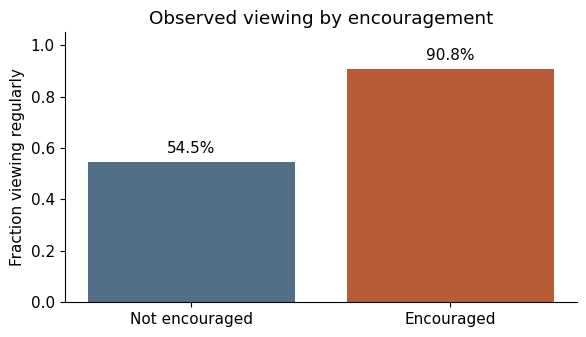

In [5]:
by_z = sesame.groupby("encour").agg(
    n=("y", "size"), viewing_rate=("watched", "mean"),
    mean_score=("y", "mean"), mean_pretest=("pretest", "mean"),
)
by_z.index.name = "Encouragement Z"
display(by_z.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar([0, 1], by_z.viewing_rate, color=[BLUE, ORANGE])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in by_z.viewing_rate], padding=4)
ax.set(xticks=[0, 1], xticklabels=["Not encouraged", "Encouraged"],
       ylabel="Fraction viewing regularly", ylim=(0, 1.05),
       title="Observed viewing by encouragement")
fig.tight_layout()
plt.show()


### Balance is a diagnostic, not proof of independence
Compare **pretreatment** characteristics across encouragement groups. Randomization can produce chance imbalances; similar observed means do not prove that unobserved characteristics are balanced.

The site table shows realized assignment fractions. They may differ by chance even under a common assignment probability; the table alone does not establish the randomization protocol. The design documentation supplies the argument for independence.


In [6]:
baseline = sesame.assign(recorded_female=(sesame.sex == 2).astype(int))
baseline_columns = ["age", "pretest", "recorded_female"]
balance = baseline.groupby("encour")[baseline_columns].mean().T
balance.columns = ["Mean: Z=0", "Mean: Z=1"]
balance["Difference (1 - 0)"] = balance["Mean: Z=1"] - balance["Mean: Z=0"]
display(balance.round(3))

site_counts = pd.crosstab(sesame.site, sesame.encour).reindex(columns=[0, 1], fill_value=0)
assert (site_counts > 0).all().all(), "A site is missing an encouragement arm."
site_design = site_counts.rename(columns={0: "n: Z=0", 1: "n: Z=1"})
site_design["Fraction encouraged"] = site_counts[1] / site_counts.sum(axis=1)
display(site_design.round(3))


,Mean: Z=0,Mean: Z=1,Difference (1 - 0)
age,51.716,51.414,-0.301
pretest,17.045,15.296,-1.749
recorded_female,0.534,0.513,-0.021


encour,n: Z=0,n: Z=1,Fraction encouraged
site,,,
1,28,32,0.533
2,19,36,0.655
3,14,50,0.781
4,23,20,0.465
5,4,14,0.778


## 3. Compliance types and identification
A compliance type depends on **both potential treatment statuses**, not just the observed pair $(Z,S)$.

| Type | $S(0)$ | $S(1)$ |
|:--|--:|--:|
| Never-taker | 0 | 0 |
| Complier | 0 | 1 |
| Always-taker | 1 | 1 |
| Defier | 1 | 0 |

Monotonicity rules out defiers. Under that assumption, the observed groups contain:

| Observed group | Possible types |
|:--|:--|
| $Z=0,S=0$ | Never-takers or compliers |
| $Z=0,S=1$ | Always-takers |
| $Z=1,S=0$ | Never-takers |
| $Z=1,S=1$ | Always-takers or compliers |

We cannot label all encouraged viewers as compliers. Nor should we label encouraged non-viewers as defiers.

### Identify population shares, without identifying every person
Let $p_A,p_C,p_N$ denote population shares of always-takers, compliers, and never-takers. With independence and monotonicity,

$$p_A=\mathbb E[S\mid Z=0],\qquad
p_C=\mathbb E[S\mid Z=1]-\mathbb E[S\mid Z=0],\qquad
p_N=1-\mathbb E[S\mid Z=1].$$

Exclusion is not needed for these treatment-response shares. Sample analogues are estimates; they need not obey all population restrictions in every sample. A negative estimated complier share should prompt investigation, not silent clipping to zero.


In [7]:
s0_hat, s1_hat = by_z.loc[0, "viewing_rate"], by_z.loc[1, "viewing_rate"]
share_estimates = pd.Series({
    "Always-takers": s0_hat,
    "Compliers": s1_hat - s0_hat,
    "Never-takers": 1 - s1_hat,
}, name="Estimated population share (pooled assumptions)")
assert np.isclose(share_estimates.sum(), 1)
display(share_estimates.to_frame().round(4))


,Estimated population share (pooled assumptions)
Always-takers,0.5455
Compliers,0.3624
Never-takers,0.0921


### Parameter → identification → estimator → estimate
The causal **parameter** is the local average treatment effect:

$$\tau_C=\operatorname{LATE}
=\mathbb E[Y(1)-Y(0)\mid S(1)>S(0)].$$

This is a mean of individual causal effects among people whose viewing would change because of encouragement. It need not equal the population ATE, $\mathbb E[Y(1)-Y(0)]$, or the ATT.

For **identification**, define the population first stage $\Delta_S$ and reduced form $\Delta_Y$:

$$\Delta_S=\mathbb E[S\mid Z=1]-\mathbb E[S\mid Z=0]=p_C,$$
$$\Delta_Y=\mathbb E[Y\mid Z=1]-\mathbb E[Y\mid Z=0]=p_C\tau_C.$$

Encouragement changes treatment only for compliers, so only their outcomes change. Independence permits comparison across encouragement groups; monotonicity removes defiers. Relevance makes the denominator nonzero. Thus

$$\tau_C=\frac{\Delta_Y}{\Delta_S}
=\frac{\operatorname{Cov}(Z,Y)}{\operatorname{Cov}(Z,S)}.$$

These are population equalities, not finite-sample identities with the true causal effect. We do **not** need a constant-effect model to identify this LATE. With heterogeneous effects, a different instrument may identify a different complier group.

### Exercise 2: shares and observability
In a hypothetical population, 30% view regularly without encouragement and 70% with encouragement. Assume independence and monotonicity.
1. What are the three compliance shares?
2. Can you identify which encouraged viewers are compliers?

<details><summary>Answer</summary>
<p>The shares are 30% always-takers, 40% compliers, and 30% never-takers. These population shares do not reveal each person's type. An encouraged viewer could be an always-taker or a complier; their viewing status without encouragement is unobserved.</p>
</details>


## 4. First stage, ITT, and Wald estimation
Let $\bar Y_z$ and $\bar S_z$ be sample means among observations with $Z=z$. The **Wald estimator** replaces the population contrasts with sample contrasts:

$$\widehat\tau_{\mathrm{Wald}}
=\frac{\bar Y_1-\bar Y_0}{\bar S_1-\bar S_0}
=\frac{\widehat\Delta_Y}{\widehat\Delta_S}.$$


The reduced form $\Delta_Y$ is the **intention-to-treat (ITT) effect of encouragement** under random assignment in the analysis population. It includes every pathway from encouragement to scores. It is not the direct effect of encouragement holding viewing fixed. An ITT interpretation does not require exclusion or monotonicity; the LATE interpretation of the ratio does.


In [8]:
first_stage_hat = s1_hat - s0_hat
itt_hat = by_z.loc[1, "mean_score"] - by_z.loc[0, "mean_score"]
if np.isclose(first_stage_hat, 0):
    raise ValueError("The sample first stage is zero; the Wald ratio is undefined.")
wald_hat = itt_hat / first_stage_hat

cov_zy = np.cov(sesame.encour, sesame.y, ddof=1)[0, 1]
cov_zs = np.cov(sesame.encour, sesame.watched, ddof=1)[0, 1]
wald_from_cov = cov_zy / cov_zs
assert np.isclose(wald_hat, wald_from_cov)

naive_gap = sesame.groupby("watched").y.mean().diff().loc[1]
results = pd.DataFrame({
    "Estimate": [100 * first_stage_hat, itt_hat, wald_hat, naive_gap],
    "Units": ["percentage points in viewing", "score points", "score points", "score points"],
}, index=["First stage", "Reduced form / ITT", "Wald IV", "Naive viewer-minus-nonviewer gap"])
display(results.round(3))
print(f"Wald calculation: {itt_hat:.4f} / {first_stage_hat:.4f} = {wald_hat:.4f}")
print(f"Same estimate using covariances: {wald_from_cov:.4f}")


,Estimate,Units
First stage,36.244,percentage points in viewing
Reduced form / ITT,2.876,score points
Wald IV,7.934,score points
Naive viewer-minus-nonviewer gap,12.689,score points


Wald calculation: 2.8756 / 0.3624 = 7.9340
Same estimate using covariances: 7.9340


The first stage is about **36.24 percentage points**, the reduced form about **2.88 score points**, and the Wald estimate about **7.93 score points**.

**Conditional interpretation:** if the pooled IV assumptions hold, the Wald estimate describes the average effect of regular viewing for children whose viewing status would change with encouragement. It is not the effect for all children or all encouraged viewers, and uncertainty still matters. Because the original design randomized within sites, we also examine site-adjusted estimation below.

The naive viewer/non-viewer difference compares selected groups. It is not generally a causal estimate, and its difference from IV is not itself a formal test of instrument validity.

### Exercise 3: compute and interpret a ratio
A hypothetical randomized encouragement raises participation from 0.20 to 0.50 and raises mean outcomes from 40 to 43. Compute the first stage, ITT, and Wald estimate. What if encouragement also affects outcomes directly?

<details><summary>Answer and Python</summary>
<p>The first stage is 0.30 (30 percentage points), the ITT is 3 points, and the Wald estimate is 10 points. Under the IV assumptions, 10 estimates the treatment effect for compliers. A direct effect violates exclusion: the randomized contrast still estimates the total effect of encouragement, but dividing by the first stage no longer isolates the treatment LATE.</p>
<pre><code>first_stage = 0.50 - 0.20
itt = 43 - 40
wald = itt / first_stage
print(first_stage, itt, wald)</code></pre>
</details>


## 5. Two-stage least squares and uncertainty
### Two regressions for the point estimate
With one instrument, one endogenous treatment, an intercept, and no controls:

1. **First stage:** regress $S_i$ on $1,Z_i$; save $\widehat S_i$.
2. **Second stage:** regress $Y_i$ on $1,\widehat S_i$.

The resulting slope equals the Wald estimate on the same rows. The first stage is a **linear** regression even when treatment is binary. Replacing it with logistic fitted probabilities is not the same 2SLS procedure.


In [10]:
first_stage = smf.ols("watched ~ encour", data=sesame).fit()
manual_data = sesame.assign(predicted_watched=first_stage.fittedvalues)
second_stage = smf.ols("y ~ predicted_watched", data=manual_data).fit()
manual_2sls = second_stage.params["predicted_watched"]

# Brackets specify the endogenous treatment and its excluded instrument.
iv_fit = IV2SLS.from_formula("y ~ 1 + [watched ~ encour]", data=sesame).fit(
    cov_type="robust"
)
assert np.isclose(manual_2sls, wald_hat)
assert np.isclose(iv_fit.params["watched"], wald_hat)
display(pd.Series({
    "Wald mean ratio": wald_hat,
    "Covariance ratio": wald_from_cov,
    "Manual 2SLS slope": manual_2sls,
    "IV2SLS slope": iv_fit.params["watched"],
}, name="Point estimate").to_frame().round(4))


,Point estimate
Wald mean ratio,7.934
Covariance ratio,7.934
Manual 2SLS slope,7.934
IV2SLS slope,7.934


### Use the assignment design and report uncertainty
We also fit `y ~ 1 + C(site) + [watched ~ encour]`. Here `C(site)` includes site indicators in the outcome equation **and** the instrument set; the first stage also controls for site. This uses within-site encouragement variation. It can have a causal interpretation under **conditional** IV assumptions within sites, with positive first stages and sufficient overlap. The target is a weighted average of site-specific LATEs, not automatically the overall ATE (see Optional A).

The following intervals use heteroskedasticity-robust IV standard errors and a large-sample normal approximation. They treat children as independent observations and require an adequate first stage. This teaching analysis does not reconstruct every feature of the original sampling design. Robust standard errors do not fix an invalid instrument, weak identification, or unmodeled dependence. See the [IV2SLS covariance documentation](https://bashtage.github.io/linearmodels/iv/iv/linearmodels.iv.model.IV2SLS.fit.html).


In [11]:
site_iv_fit = IV2SLS.from_formula(
    "y ~ 1 + C(site) + [watched ~ encour]", data=sesame
).fit(cov_type="robust")

inference_rows = []
for label, fit in [("Pooled IV", iv_fit), ("IV with site indicators", site_iv_fit)]:
    interval = fit.conf_int().loc["watched"]
    inference_rows.append({
        "Model": label, "IV estimate": fit.params["watched"],
        "Robust SE": fit.std_errors["watched"],
        "95% lower": interval.iloc[0], "95% upper": interval.iloc[1],
    })
inference_table = pd.DataFrame(inference_rows).set_index("Model")
display(inference_table.round(3))


,IV estimate,Robust SE,95% lower,95% upper
Model,,,,
Pooled IV,7.934,4.614,-1.109,16.977
IV with site indicators,9.784,4.543,0.880,18.688


Read the interval as well as the point estimate. An interval containing zero does not prove that the effect is zero; it indicates that these data and this approximation do not sharply distinguish zero from other plausible effects. A difference between pooled and adjusted estimates can reflect covariate imbalance, weighting, and sampling variation.



## 6. Weak instruments
### Relevance is not the same as strength
A population first stage may be nonzero yet too small to estimate the ratio precisely at the available sample size. Sampling error in a small denominator can create extreme estimates and unreliable conventional intervals. Strength depends on the signal **relative to its uncertainty**, not only the size of the coefficient.

For one excluded instrument, the conventional first-stage $F$ equals the squared conventional $t$ statistic on that instrument. With controls, test the **excluded instrument**, not whether all first-stage coefficients, including controls, are jointly zero.


In [ ]:
# Conventional homoskedastic diagnostic, to match the 2025 lab.
conventional_f = float(first_stage.fvalue)
assert np.isclose(conventional_f, first_stage.tvalues["encour"] ** 2)
print(f"Pooled conventional first-stage F: {conventional_f:.2f}")

# Robust diagnostics for both models; inspect the reference distribution.
for label, fit in [("Pooled", iv_fit), ("Site adjusted", site_iv_fit)]:
    print(f"\n{label}: excluded-instrument diagnostics")
    diagnostics = fit.first_stage.diagnostics[
        ["partial.rsquared", "f.stat", "f.pval", "f.dist"]
    ].copy()
    diagnostics["f.pval"] = diagnostics["f.pval"].map(lambda p: f"{p:.2e}")
    display(diagnostics.round(4))


Pooled conventional first-stage F: 50.46

Pooled: excluded-instrument diagnostics


,partial.rsquared,f.stat,f.pval,f.dist
watched,0.1749,39.0082,4.22e-10,chi2(1)



Site adjusted: excluded-instrument diagnostics


,partial.rsquared,f.stat,f.pval,f.dist
watched,0.1767,41.605,1.12e-10,chi2(1)


The conventional pooled $F$ is about **50.46**. The familiar “$F>10$” rule is a rough diagnostic, not a certificate of instrument validity or reliable inference in every setting. No first-stage statistic tests exclusion or rules out defiers.


### Synthetic demonstration: a small denominator
In each simulated dataset, randomly encourage half the population on average. Set the always-taker share to 0.30, the complier share to either 0.50 or 0.03, and the remaining share to never-takers. Define both potential treatment statuses and both potential outcomes **before** assigning encouragement.

Every person's treatment effect is **8 synthetic points**, so the population ATE, LATE, and finite-sample average effect are all 8. Baseline outcomes differ by compliance type, making actual treatment selected. The IV assumptions hold by construction, even in the small-first-stage scenario. Each replication draws a fresh sample of 500 people; we run 600 replications per scenario.


,Median,5th percentile,95th percentile,Undefined ratios,Nonpositive sample first stages
Scenario,,,,,
Larger first stage,8.06,4.15,11.29,0,0
Smaller first stage,17.01,-116.75,106.65,1,109


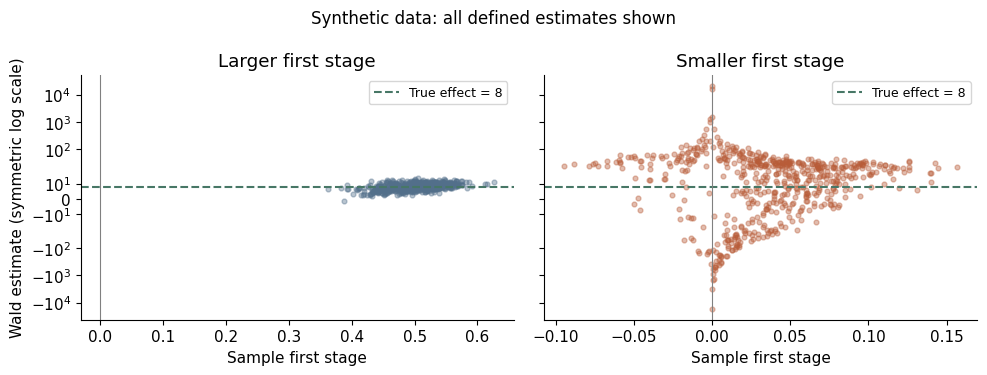

In [12]:
def simulate_wald(complier_share, rng, n=500):
    """Return sample first stage and Wald estimate from one synthetic sample."""
    type_draw = rng.uniform(size=n)
    always = type_draw < 0.30
    complier = (type_draw >= 0.30) & (type_draw < 0.30 + complier_share)
    s0 = always.astype(int)
    s1 = (always | complier).astype(int)
    y0 = 20 + 10 * always - 5 * (~(always | complier)) + rng.normal(0, 10, n)
    y1 = y0 + 8

    z = rng.binomial(1, 0.5, n)  # independent of all potential values above
    s = np.where(z == 1, s1, s0)
    y = np.where(s == 1, y1, y0)
    if z.min() == z.max():
        return np.nan, np.nan  # no comparison arm
    fs = s[z == 1].mean() - s[z == 0].mean()
    rf = y[z == 1].mean() - y[z == 0].mean()
    estimate = np.nan if abs(fs) < 1e-12 else rf / fs
    return fs, estimate

weak_rng = np.random.default_rng(102601)
replications = 600
simulation_rows = []
for label, complier_share in [("Larger first stage", 0.50), ("Smaller first stage", 0.03)]:
    for _ in range(replications):
        fs, estimate = simulate_wald(complier_share, weak_rng)
        simulation_rows.append({
            "Scenario": label, "First stage": fs, "Wald estimate": estimate,
        })
simulations = pd.DataFrame(simulation_rows)
summary_rows = []
for label, group in simulations.groupby("Scenario", sort=False):
    finite = group["Wald estimate"].dropna()
    summary_rows.append({
        "Scenario": label,
        "Median": finite.median(), "5th percentile": finite.quantile(0.05),
        "95th percentile": finite.quantile(0.95),
        "Undefined ratios": group["Wald estimate"].isna().sum(),
        "Nonpositive sample first stages": (group["First stage"] <= 0).sum(),
    })
display(pd.DataFrame(summary_rows).set_index("Scenario").round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (label, group), color in zip(
    axes, simulations.groupby("Scenario", sort=False), [BLUE, ORANGE]
):
    ax.scatter(group["First stage"], group["Wald estimate"], s=12, alpha=0.4, color=color)
    ax.axhline(8, color=GREEN, linestyle="--", label="True effect = 8")
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set(xlabel="Sample first stage", title=label)
    ax.set_yscale("symlog", linthresh=20)
    ax.legend(fontsize=9)
axes[0].set_ylabel("Wald estimate (symmetric log scale)")
fig.suptitle("Synthetic data: all defined estimates shown", fontsize=12)
fig.tight_layout()
plt.show()


The smaller first stage produces much more variable estimates, including sign reversals. This can happen even though the causal effect is positive and monotonicity holds in the population. The plot uses a symmetric log scale to display extreme values without dropping them; undefined ratios are counted in the table. The reported simulation percentiles describe repeated estimates, not a confidence interval from a single dataset.

### Exit exercise: interpret before reporting
1. Why is the reduced form not itself the effect of viewing?
2. Does a positive first stage prove that no child is a defier?
3. If the true first stage is 0.02, how much does a 0.5-point error in the reduced form change the ratio, holding the denominator fixed?

<details><summary>Answers</summary>
<ol>
<li>The reduced form compares encouragement groups. Under random assignment it estimates the total effect of encouragement, which changes viewing only for some children.</li>
<li>No. Without monotonicity, the population first stage is the complier share minus the defier share; it can be positive with defiers present. Monotonicity needs a substantive argument.</li>
<li>The ratio changes by $0.5/0.02=25$ points. Randomness in the denominator can create further instability.</li>
</ol>
</details>



## Optional. Collider bias
A **collider** is a common effect of two variables. Conditioning on it can create an association between otherwise independent causes.

Return to the 2025 lab's synthetic model:

$$S\sim N(0,1),\quad Y\sim N(0,1),\quad \varepsilon\sim N(0,1)
\quad\text{independently},\qquad C=2S+2Y+\varepsilon.$$

Here the graph is $S\to C\leftarrow Y$. The causal effect of $S$ on $Y$ is zero by construction. Select observations with $C$ above its sample 90th percentile. Among selected observations, a lower $S$ tends to require a higher $Y$ to qualify, inducing negative association. This example is about selection on $C$, not evidence that $S$ causes $Y$.


Full-sample correlation: 0.017
Selected-sample correlation: -0.595


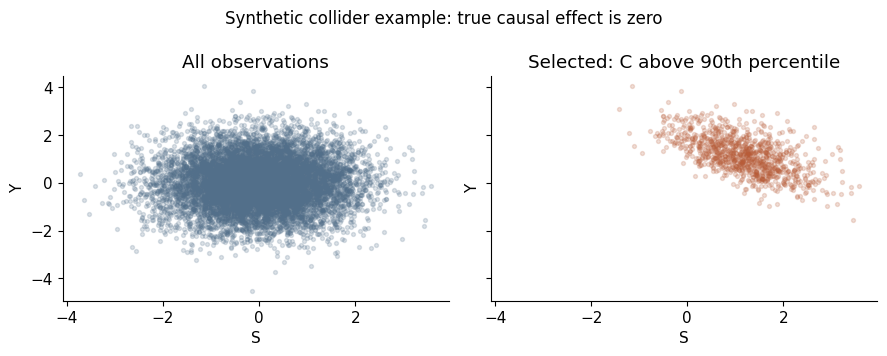

In [13]:
collider_rng = np.random.default_rng(102602)
n_collider = 10000
s = collider_rng.normal(size=n_collider)
y = collider_rng.normal(size=n_collider)
c = 2 * s + 2 * y + collider_rng.normal(size=n_collider)
collider_data = pd.DataFrame({"S": s, "Y": y, "C": c})
selected = collider_data.loc[collider_data.C > collider_data.C.quantile(0.90)]
print(f"Full-sample correlation: {collider_data.S.corr(collider_data.Y):.3f}")
print(f"Selected-sample correlation: {selected.S.corr(selected.Y):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
for ax, data, title, color in [
    (axes[0], collider_data, "All observations", BLUE),
    (axes[1], selected, "Selected: C above 90th percentile", ORANGE),
]:
    ax.scatter(data.S, data.Y, s=8, alpha=0.2, color=color, rasterized=True)
    ax.set(xlabel="S", ylabel="Y", title=title)
fig.suptitle("Synthetic collider example: true causal effect is zero", fontsize=12)
fig.tight_layout()
plt.show()


### Optional exercise: connect back to IV
If study inclusion were a common effect of encouragement and unobserved family resources, why might analyzing only included children undermine IV independence?

<details><summary>Answer</summary>
<p>In the graph $Z\to R\leftarrow U\to Y$, inclusion $R$ is a collider. Conditioning on inclusion can associate the instrument $Z$ with $U$, even if encouragement was randomized before selection. Randomization in the original population does not automatically establish independence in a selected sample. This is a hypothetical concern, not a claim that this mechanism generated the Sesame Street file.</p>
</details>


